In [1]:
## 셀 1 — Colab 환경 진단 (변경 없음, 출력만)

import sys
print(f"Python: {sys.version.split()[0]}")
print()

# 핵심 패키지 버전
print("[현재 패키지 버전]")
for pkg in ['numpy', 'scipy', 'cv2', 'PIL', 'pandas', 'matplotlib']:
    try:
        if pkg == 'PIL':
            import PIL
            v = PIL.__version__
        elif pkg == 'cv2':
            import cv2
            v = cv2.__version__
        else:
            mod = __import__(pkg)
            v = getattr(mod, '__version__', '?')
        print(f"  {pkg:12s}: {v}")
    except Exception as e:
        print(f"  {pkg:12s}: 에러 ({type(e).__name__})")


# 본인 venv 정본 비교
print("\n[본인 venv 정본 (목표)]")
print("  numpy       : 1.26.4")
print("  scipy       : 1.17.1")
print("  cv2         : 4.10.0")
print("  PIL         : 10.4.0")
print("  pandas      : 2.2.3")


# GPU 확인
print("\n[GPU]")
import subprocess
try:
    result = subprocess.run(
        ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
        capture_output=True, text=True, timeout=5
    )
    out = result.stdout.strip()
    print(f"  {out if out else '(GPU 없음)'}")
except Exception as e:
    print(f"  nvidia-smi 사용 불가")


# rembg 미설치 확인
print("\n[rembg]")
try:
    import rembg
    print(f"  설치됨: {rembg.__version__}")
except ImportError:
    print(f"  미설치 (다음 셀에서 설치)")

Python: 3.11.13

[현재 패키지 버전]
  numpy       : 2.0.2
  scipy       : 1.15.3
  cv2         : 4.12.0
  PIL         : 11.2.1
  pandas      : 2.2.2
  matplotlib  : 3.10.0

[본인 venv 정본 (목표)]
  numpy       : 1.26.4
  scipy       : 1.17.1
  cv2         : 4.10.0
  PIL         : 10.4.0
  pandas      : 2.2.3

[GPU]
  Tesla T4, 15360 MiB

[rembg]
  미설치 (다음 셀에서 설치)


In [2]:
## 셀 2 — 본인 venv 정본 환경으로 정정

!pip install --quiet \
  "numpy==1.26.4" \
  "scipy==1.17.1" \
  "opencv-python==4.10.0.84" \
  "pillow==10.4.0" \
  "pandas==2.2.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 8.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 107.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 156.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 130.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.2.3 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have

In [1]:
## 셀 3 — 정정 결과 검증

# 런타임 재시작 없이 새로 import 하기 위한 모듈 캐시 초기화
import importlib
import sys

# 영향받은 모듈들 캐시 제거
for mod_name in list(sys.modules.keys()):
    if any(mod_name.startswith(p) for p in ['numpy', 'scipy', 'cv2', 'PIL', 'pandas', 'matplotlib']):
        del sys.modules[mod_name]

# 재 import
import numpy
import scipy
import cv2
import PIL
import pandas

print("[정정 후 버전]")
print(f"  numpy   : {numpy.__version__}")
print(f"  scipy   : {scipy.__version__}")
print(f"  cv2     : {cv2.__version__}")
print(f"  PIL     : {PIL.__version__}")
print(f"  pandas  : {pandas.__version__}")

/tmp/ipython-input-1-2226747911.py:13: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy


[정정 후 버전]
  numpy   : 1.26.4
  scipy   : 1.17.1
  cv2     : 4.10.0
  PIL     : 10.4.0
  pandas  : 2.2.3


In [2]:
import cv2
print(f"cv2 path: {cv2.__file__}")

cv2 path: /usr/local/lib/python3.11/dist-packages/cv2/__init__.py


In [3]:
!pip show opencv-python opencv-python-headless 2>&1

Name: opencv-python
Version: 4.10.0.84
Summary: Wrapper package for OpenCV python bindings.
Home-page: https://github.com/opencv/opencv-python
Author: 
Author-email: 
License: Apache 2.0
Location: /usr/local/lib/python3.11/dist-packages
Requires: numpy
Required-by: dopamine_rl
---
Name: opencv-python-headless
Version: 4.12.0.88
Summary: Wrapper package for OpenCV python bindings.
Home-page: https://github.com/opencv/opencv-python
Author: 
Author-email: 
License: Apache 2.0
Location: /usr/local/lib/python3.11/dist-packages
Requires: numpy
Required-by: albucore, albumentations


In [4]:
## opencv-python-headless 제거 + opencv-python 4.10 강제 재설치

!pip uninstall -y opencv-python-headless
!pip install --force-reinstall --no-deps "opencv-python==4.10.0.84"

Found existing installation: opencv-python-headless 4.12.0.88
Uninstalling opencv-python-headless-4.12.0.88:
  Successfully uninstalled opencv-python-headless-4.12.0.88
  Using cached opencv_python-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (62.5 MB)
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.10.0.84
    Uninstalling opencv-python-4.10.0.84:
      Successfully uninstalled opencv-python-4.10.0.84


In [1]:
import sys
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith('cv2'):
        del sys.modules[mod_name]

import cv2
print(f"cv2: {cv2.__version__}")
print(f"cv2 path: {cv2.__file__}")

cv2: 4.10.0
cv2 path: /usr/local/lib/python3.11/dist-packages/cv2/__init__.py


In [3]:
## 셀 — Drive API 인증 + dataset 폴더 검색

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Drive API 인증
from google.colab import auth
auth.authenticate_user()

from googleapiclient.discovery import build
drive_service = build('drive', 'v3')


# ── Colab 작업 디렉토리 ──
ROOT = Path('/content/work')
ROOT.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR = ROOT / 'analysis'
FIG_DIR = ANALYSIS_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 다운로드 후 위치들
DATASET_ZIP_LOCAL = Path('/content/dataset_yolo.zip')
DATASET_YOLO_DIR = Path('/content/dataset_yolo')
CLEAN_DF_LOCAL = Path('/content/clean_df.csv')


# ── dataset 폴더 검색 ──
print("=" * 60)
print("[Drive API] dataset 폴더 검색")
print("=" * 60)

results = drive_service.files().list(
    q="name='dataset' and mimeType='application/vnd.google-apps.folder' and trashed=false",
    fields='files(id, name, parents)'
).execute()
dataset_folders = results.get('files', [])

print(f"매칭: {len(dataset_folders)}건")
for f in dataset_folders:
    print(f"  id={f['id']}, name={f['name']}, parents={f.get('parents', [])}")

assert len(dataset_folders) >= 1, "dataset 폴더 없음. Drive 위치 확인 필요"
DATASET_FOLDER_ID = dataset_folders[0]['id']  # 1개만 있다 가정
print(f"\nDATASET_FOLDER_ID = {DATASET_FOLDER_ID}")


# ── dataset 폴더 안 파일 list ──
print("\n" + "=" * 60)
print("[dataset 폴더 안 파일]")
print("=" * 60)

results = drive_service.files().list(
    q=f"'{DATASET_FOLDER_ID}' in parents and trashed=false",
    fields='files(id, name, size, mimeType)',
    pageSize=100
).execute()

files_in_dataset = results.get('files', [])
print(f"파일 수: {len(files_in_dataset)}")

dataset_zip_id = None
clean_df_id = None
for f in files_in_dataset:
    size_mb = int(f.get('size', 0)) / 1024 / 1024 if f.get('size') else 0
    is_dir = f['mimeType'] == 'application/vnd.google-apps.folder'
    tag = '[DIR]' if is_dir else '[FILE]'
    print(f"  {tag} {f['name']:50s}  {size_mb:>8.1f} MB  id={f['id']}")

    if f['name'] == 'dataset_yolo.zip' and not is_dir:
        dataset_zip_id = f['id']
    elif f['name'] == 'clean_df.csv' and not is_dir:
        clean_df_id = f['id']

print(f"\n[캐싱]")
print(f"  dataset_yolo.zip Drive ID: {dataset_zip_id}")
print(f"  clean_df.csv     Drive ID: {clean_df_id}")
assert dataset_zip_id, "dataset_yolo.zip 없음 in dataset 폴더"
assert clean_df_id, "clean_df.csv 없음 in dataset 폴더"

[Drive API] dataset 폴더 검색
매칭: 1건
  id=1DpPjeJU4IpNrEzc9zNxVehPl8TzElyzF, name=dataset, parents=['18pR481upi_Bhgika5IT0OQ63QLGGcSJj']

DATASET_FOLDER_ID = 1DpPjeJU4IpNrEzc9zNxVehPl8TzElyzF

[dataset 폴더 안 파일]
파일 수: 4
  [FILE] dataset_yolo.zip의 사본                                 17926.7 MB  id=1miPs4XRtLP1noLnfSQrbQyA-95XnKIM0
  [FILE] synthetic_combined.zip                                3260.1 MB  id=1QvVnq7n-1_VNbJ6AZkbTjqZNwru4m92i
  [FILE] dataset_yolo.zip                                     17926.7 MB  id=1xeE2mlCVcaxlhc98icP_Di7FKQfgAtlj
  [FILE] clean_df.csv                                            28.1 MB  id=1LcpqnTI_v6sNrIzk1-H9B4gmnAmzuUv9

[캐싱]
  dataset_yolo.zip Drive ID: 1xeE2mlCVcaxlhc98icP_Di7FKQfgAtlj
  clean_df.csv     Drive ID: 1LcpqnTI_v6sNrIzk1-H9B4gmnAmzuUv9


In [4]:
## 셀 — dataset_yolo.zip + clean_df.csv 다운로드

import time
from googleapiclient.http import MediaIoBaseDownload


def download_drive_file(file_id, out_path, chunksize_mb=200, label=''):
    """Drive 파일 다운로드. 같은 크기 파일 이미 있으면 스킵."""
    out_path = Path(out_path)

    # 메타 (size) 조회
    meta = drive_service.files().get(fileId=file_id, fields='size, name').execute()
    expected_size = int(meta['size'])

    # 이미 있고 크기 일치하면 스킵
    if out_path.exists() and out_path.stat().st_size == expected_size:
        size_gb = expected_size / 1e9
        print(f"  {label or out_path.name}: 이미 있음 ({size_gb:.1f} GB), 스킵")
        return

    print(f"\n=== {label or meta['name']} 다운로드 ({expected_size/1e9:.2f} GB) ===")
    request = drive_service.files().get_media(fileId=file_id)

    t0 = time.time()
    with open(out_path, 'wb') as fp:
        downloader = MediaIoBaseDownload(fp, request, chunksize=chunksize_mb*1024*1024)
        done = False
        last_pct = -1
        while not done:
            status, done = downloader.next_chunk()
            if status:
                pct = int(status.progress() * 100)
                if pct >= last_pct + 5:
                    print(f"  {pct}%")
                    last_pct = pct

    elapsed = time.time() - t0
    size_gb = out_path.stat().st_size / 1e9
    speed = size_gb * 1024 / elapsed
    print(f"  완료: {size_gb:.2f} GB / {elapsed:.0f}초 / {speed:.0f} MB/s")


# ── clean_df.csv (작은 파일, chunksize 10MB) ──
download_drive_file(clean_df_id, CLEAN_DF_LOCAL, chunksize_mb=10, label='clean_df.csv')

# ── dataset_yolo.zip (큰 파일, chunksize 200MB) ──
download_drive_file(dataset_zip_id, DATASET_ZIP_LOCAL, chunksize_mb=200, label='dataset_yolo.zip')


# ── 검증 ──
print("\n" + "=" * 60)
print("[다운로드 검증]")
print("=" * 60)
print(f"  clean_df.csv     : {CLEAN_DF_LOCAL.stat().st_size / 1e6:.1f} MB")
print(f"  dataset_yolo.zip : {DATASET_ZIP_LOCAL.stat().st_size / 1e9:.2f} GB")


# ── clean_df 로드 ──
df_clean = pd.read_csv(CLEAN_DF_LOCAL, low_memory=False)
print(f"\n[clean_df 로드]")
print(f"  shape: {df_clean.shape}")
print(f"  columns 개수: {len(df_clean.columns)}")
print(f"  unique file_name: {df_clean['file_name'].nunique()}")


=== clean_df.csv 다운로드 (0.03 GB) ===
  35%
  71%
  100%
  완료: 0.03 GB / 6초 / 5 MB/s

=== dataset_yolo.zip 다운로드 (18.80 GB) ===
  4%
  10%
  15%
  20%
  25%
  30%
  35%
  40%
  45%
  50%
  55%
  60%
  65%
  70%
  75%
  80%
  85%
  90%
  95%
  100%
  완료: 18.80 GB / 311초 / 62 MB/s

[다운로드 검증]
  clean_df.csv     : 29.5 MB
  dataset_yolo.zip : 18.80 GB

[clean_df 로드]
  shape: (39864, 45)
  columns 개수: 45
  unique file_name: 10392


In [5]:
## 셀 — dataset_yolo.zip 압축 해제 + 카운트 검증

import zipfile
from tqdm.auto import tqdm

# 이미 풀려있으면 스킵
DATASET_YOLO_DIR = Path('/content/dataset_yolo')
TRAIN_DIR = DATASET_YOLO_DIR / 'images' / 'train'
VAL_DIR = DATASET_YOLO_DIR / 'images' / 'val'

EXPECTED_TRAIN = 8302
EXPECTED_VAL = 2090

if (TRAIN_DIR.exists() and VAL_DIR.exists() and
    len(list(TRAIN_DIR.iterdir())) >= EXPECTED_TRAIN and
    len(list(VAL_DIR.iterdir())) >= EXPECTED_VAL):
    print("이미 풀려있음, 스킵")
else:
    print(f"=== {DATASET_ZIP_LOCAL.name} 압축 해제 ===")
    DATASET_YOLO_DIR.mkdir(parents=True, exist_ok=True)

    t0 = time.time()
    with zipfile.ZipFile(DATASET_ZIP_LOCAL, 'r') as zf:
        members = zf.namelist()
        print(f"  파일 수: {len(members)}")

        for m in tqdm(members, desc='압축 해제'):
            zf.extract(m, DATASET_YOLO_DIR)

    elapsed = time.time() - t0
    print(f"  완료: {elapsed:.0f}초")


# ── 검증 ──
print("\n" + "=" * 60)
print("[압축 해제 검증]")
print("=" * 60)

# zip 안 구조 확인 (중첩 여부)
items_in_root = sorted(DATASET_YOLO_DIR.iterdir())
print(f"DATASET_YOLO_DIR 직접 하위:")
for p in items_in_root[:10]:
    if p.is_dir():
        n = len(list(p.iterdir()))
        print(f"  [DIR]  {p.name}/  ({n}개)")
    else:
        size_mb = p.stat().st_size / 1024 / 1024
        print(f"  [FILE] {p.name}  ({size_mb:.1f} MB)")


# 학습 노트북에서 확인된 평면 구조 패턴
# /content/dataset_yolo/dataset_yolo/images/train/...  같은 중첩일 수도
# 또는 /content/dataset_yolo/images/train/...  평면일 수도
# 자동 탐색
candidates = [
    DATASET_YOLO_DIR / 'images' / 'train',
    DATASET_YOLO_DIR / 'dataset_yolo' / 'images' / 'train',
]
TRAIN_DIR_FINAL = None
VAL_DIR_FINAL = None
for c in candidates:
    if c.exists():
        TRAIN_DIR_FINAL = c
        VAL_DIR_FINAL = c.parent / 'val'
        break

assert TRAIN_DIR_FINAL is not None, "train 폴더 위치 자동 탐색 실패"
print(f"\n  TRAIN: {TRAIN_DIR_FINAL}")
print(f"  VAL  : {VAL_DIR_FINAL}")

n_train = len(list(TRAIN_DIR_FINAL.iterdir()))
n_val = len(list(VAL_DIR_FINAL.iterdir())) if VAL_DIR_FINAL.exists() else 0
print(f"\n  train 파일: {n_train} (박제값 {EXPECTED_TRAIN})")
print(f"  val   파일: {n_val} (박제값 {EXPECTED_VAL})")

assert n_train == EXPECTED_TRAIN, f"train 파일 수 불일치: {n_train} vs {EXPECTED_TRAIN}"
assert n_val == EXPECTED_VAL, f"val 파일 수 불일치: {n_val} vs {EXPECTED_VAL}"

# 본 노트북에서 사용할 변수 갱신
DATASET_YOLO_DIR = TRAIN_DIR_FINAL.parent.parent  # train 의 상위 2단계 = 루트
print(f"\n[갱신] DATASET_YOLO_DIR = {DATASET_YOLO_DIR}")

=== dataset_yolo.zip 압축 해제 ===
  파일 수: 20791


압축 해제:   0%|          | 0/20791 [00:00<?, ?it/s]

  완료: 89초

[압축 해제 검증]
DATASET_YOLO_DIR 직접 하위:
  [DIR]  images/  (2개)
  [DIR]  labels/  (2개)
  [FILE] pill.yaml  (0.0 MB)

  TRAIN: /content/dataset_yolo/images/train
  VAL  : /content/dataset_yolo/images/val

  train 파일: 8302 (박제값 8302)
  val   파일: 2090 (박제값 2090)

[갱신] DATASET_YOLO_DIR = /content/dataset_yolo


[한글 폰트]
  Drive 에서 NanumGothic.ttf 발견 (id=18PL2_P471X-WVyTV8YmOWfxspguYCBoo)
  다운로드 완료: 4581.9 KB
  matplotlib 폰트 적용: NanumGothic

[측정 풀]
  pool_df: 39131행 (clean_df 39864 중 NaN 733 제외)


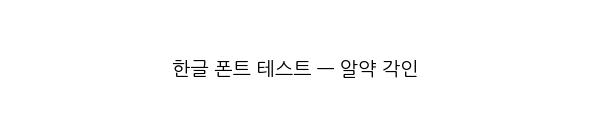

In [6]:
## 셀 — 헬퍼 함수 + 한글 폰트 + 측정 풀 준비

# ── 헬퍼: 한국어 경로 이미지 로드 ──
def imread_kr(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)


# ── 헬퍼: file_name → 이미지 경로 ──
TRAIN_DIR = DATASET_YOLO_DIR / 'images' / 'train'
VAL_DIR = DATASET_YOLO_DIR / 'images' / 'val'

def find_image_path(file_name):
    """train/val 양쪽 검사. 둘 다 없으면 None."""
    p_train = TRAIN_DIR / file_name
    if p_train.exists():
        return p_train
    p_val = VAL_DIR / file_name
    if p_val.exists():
        return p_val
    return None


# ── 한글 폰트 — Drive API 로 NanumGothic.ttf 다운로드 ──
print("=" * 60)
print("[한글 폰트]")
print("=" * 60)

NANUM_LOCAL = Path('/content/NanumGothic.ttf')

if not NANUM_LOCAL.exists():
    # MyDrive 루트에서 NanumGothic.ttf 검색
    res = drive_service.files().list(
        q="name='NanumGothic.ttf' and trashed=false",
        fields='files(id, name, size, parents)'
    ).execute()
    nanum_files = res.get('files', [])

    if nanum_files:
        nanum_id = nanum_files[0]['id']
        print(f"  Drive 에서 NanumGothic.ttf 발견 (id={nanum_id})")
        request = drive_service.files().get_media(fileId=nanum_id)
        with open(NANUM_LOCAL, 'wb') as fp:
            from googleapiclient.http import MediaIoBaseDownload
            downloader = MediaIoBaseDownload(fp, request, chunksize=5*1024*1024)
            done = False
            while not done:
                _, done = downloader.next_chunk()
        print(f"  다운로드 완료: {NANUM_LOCAL.stat().st_size / 1024:.1f} KB")
    else:
        print(f"  Drive 에 NanumGothic.ttf 없음 — apt-get 으로 설치 시도")
        os.system('apt-get install -y -qq fonts-nanum')

if NANUM_LOCAL.exists():
    fm.fontManager.addfont(str(NANUM_LOCAL))
    plt.rcParams['font.family'] = 'NanumGothic'
    print(f"  matplotlib 폰트 적용: NanumGothic")
else:
    available = {f.name for f in fm.fontManager.ttflist}
    for name in ['NanumGothic', 'Malgun Gothic', 'Gulim']:
        if name in available:
            plt.rcParams['font.family'] = name
            print(f"  시스템 폰트 사용: {name}")
            break

plt.rcParams['axes.unicode_minus'] = False


# ── 측정 풀 (image_exists notna 인 행만) ──
pool_df = df_clean[df_clean['image_exists'].notna()].reset_index(drop=True)
print(f"\n[측정 풀]")
print(f"  pool_df: {len(pool_df)}행 (clean_df {len(df_clean)} 중 NaN {len(df_clean) - len(pool_df)} 제외)")


# ── 한글 폰트 시각 검증 (간단) ──
fig, ax = plt.subplots(figsize=(6, 1.5))
ax.text(0.5, 0.5, '한글 폰트 테스트 — 알약 각인', ha='center', va='center', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.show()

In [7]:
## 셀 — 측정 함수 정의 + ABS_THRESHOLD 캘리브레이션

# ── 측정 함수 (RGB crop 전체 영역 기준) ──
def measure_kcode(rgb, abs_threshold, ksize=3, percentile=90):
    """
    RGB crop 에서 imprint 측정.

    Returns:
        dict: pill_px, ratio_pct, ratio_abs, mean_lap, mask_pct, mask_abs, lap_abs
    """
    if rgb.ndim == 3 and rgb.shape[2] == 4:
        rgb = rgb[:, :, :3]

    h, w = rgb.shape[:2]
    pill_px = h * w

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=ksize)
    lap_abs = np.abs(lap)

    pct_thr = np.percentile(lap_abs, percentile)
    mask_pct = lap_abs >= pct_thr
    mask_abs = lap_abs >= abs_threshold

    return {
        'pill_px': pill_px,
        'mask_pct': mask_pct,
        'ratio_pct': mask_pct.sum() / pill_px,
        'mask_abs': mask_abs,
        'ratio_abs': mask_abs.sum() / pill_px,
        'mean_lap': float(lap_abs[mask_pct].mean()) if mask_pct.any() else 0.0,
        'lap_abs': lap_abs,
    }


def measure_m2_kcode(rgb, scale, abs_threshold, ksize=3):
    """RGB crop → 다운샘플 → 원본 해상도 업샘플 → measure_kcode."""
    h, w = rgb.shape[:2]
    nw = max(1, int(round(w * scale)))
    nh = max(1, int(round(h * scale)))
    rgb_ds = cv2.resize(rgb, (nw, nh), interpolation=cv2.INTER_AREA)
    rgb_up = cv2.resize(rgb_ds, (w, h), interpolation=cv2.INTER_LINEAR)
    return measure_kcode(rgb_up, abs_threshold, ksize=ksize)


# ── ABS_THRESHOLD 캘리브레이션: 50개 풀 ──
print("[ABS_THRESHOLD 캘리브레이션]")

SAMPLE_FOR_THRESHOLD = 50
SEED_THR = 123
rng_thr = np.random.default_rng(SEED_THR)
sample_indices = rng_thr.choice(len(pool_df), SAMPLE_FOR_THRESHOLD, replace=False)

all_imprint_lap_values = []
n_used = 0
for idx in sample_indices:
    row = pool_df.iloc[idx]
    img_path = find_image_path(row['file_name'])
    if img_path is None:
        continue
    img_bgr = imread_kr(img_path)
    if img_bgr is None:
        continue
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    x, y, w, h = int(row['bbox_x']), int(row['bbox_y']), int(row['bbox_w']), int(row['bbox_h'])
    crop = rgb[y:y+h, x:x+w]
    if crop.size == 0:
        continue

    m = measure_kcode(crop, abs_threshold=0, ksize=3, percentile=90)
    all_imprint_lap_values.extend(m['lap_abs'][m['mask_pct']].tolist())
    n_used += 1

ABS_THRESHOLD_KCODE = float(np.percentile(all_imprint_lap_values, 25))
print(f"  사용된 ROI: {n_used} / {SAMPLE_FOR_THRESHOLD}")
print(f"  imprint 픽셀 총 수: {len(all_imprint_lap_values):,}")
print(f"  lap_abs 25 percentile (= ABS_THRESHOLD_KCODE): {ABS_THRESHOLD_KCODE:.2f}")
print(f"  lap_abs median: {np.median(all_imprint_lap_values):.2f}")
print(f"  lap_abs mean: {np.mean(all_imprint_lap_values):.2f}")

[ABS_THRESHOLD 캘리브레이션]
  사용된 ROI: 50 / 50
  imprint 픽셀 총 수: 515,181
  lap_abs 25 percentile (= ABS_THRESHOLD_KCODE): 24.00
  lap_abs median: 28.00
  lap_abs mean: 31.07


In [8]:
## 셀 — 100 ROI × 3 imgsz 측정 (M2 방법)

# ── 다운샘플 scale 정의 ──
LONG_SIDE_ORIG = 1280
DOWNSAMPLE_TARGETS = {
    640: 640 / LONG_SIDE_ORIG,
    1024: 1024 / LONG_SIDE_ORIG,
    1280: 1280 / LONG_SIDE_ORIG,
}
print("imgsz별 scale:")
for imgsz, scale in DOWNSAMPLE_TARGETS.items():
    print(f"  {imgsz}: {scale:.4f}")


# ── 100 ROI 샘플링 ──
N_SAMPLE = 100
SEED_C = 2026
rng_c = np.random.default_rng(SEED_C)
sample_idx = rng_c.choice(len(pool_df), N_SAMPLE, replace=False)
print(f"\n[샘플링] 측정 풀 {len(pool_df)} 중 {N_SAMPLE}개 (seed={SEED_C})")


# ── 측정 ──
records = []
n_skipped = 0

for i, idx in enumerate(sample_idx):
    row = pool_df.iloc[idx]
    img_path = find_image_path(row['file_name'])
    if img_path is None:
        n_skipped += 1
        continue
    img_bgr = imread_kr(img_path)
    if img_bgr is None:
        n_skipped += 1
        continue
    rgb_full = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    x, y, w, h = int(row['bbox_x']), int(row['bbox_y']), int(row['bbox_w']), int(row['bbox_h'])
    crop = rgb_full[y:y+h, x:x+w]
    if crop.size == 0 or crop.shape[0] < 8 or crop.shape[1] < 8:
        n_skipped += 1
        continue

    # 원본 측정
    m_orig = measure_kcode(crop, ABS_THRESHOLD_KCODE, ksize=3)
    base_pct = m_orig['ratio_pct']
    base_abs = m_orig['ratio_abs']
    base_lap = m_orig['mean_lap']

    if base_lap == 0 or base_abs == 0:
        n_skipped += 1
        continue

    crop_h, crop_w = crop.shape[:2]
    crop_area = crop_w * crop_h

    # imgsz 별 측정
    for imgsz, scale in DOWNSAMPLE_TARGETS.items():
        m_ds = measure_m2_kcode(crop, scale, ABS_THRESHOLD_KCODE, ksize=3)
        records.append({
            'file_name': row['file_name'],
            'dl_name': row['dl_name'],
            'class_idx_clean': row.get('class_idx', np.nan),
            'crop_w': crop_w, 'crop_h': crop_h, 'crop_area': crop_area,
            'imgsz': imgsz,
            'orig_abs_%': base_abs * 100,
            'orig_lap': base_lap,
            'pct_pres_%': m_ds['ratio_pct']/base_pct*100 if base_pct>0 else 0,
            'abs_pres_%': m_ds['ratio_abs']/base_abs*100,
            'lap_pres_%': m_ds['mean_lap']/base_lap*100,
        })

    if (i+1) % 20 == 0:
        print(f"  {i+1}/{N_SAMPLE} 완료")

df_kcode = pd.DataFrame(records)
print(f"\n측정 완료: {len(df_kcode)}행 ({len(df_kcode)//3} ROI × 3 imgsz), 스킵 {n_skipped}건")


# ── imgsz별 보존율 분포 ──
print("\n[imgsz별 보존율 분포]")
print(f"{'imgsz':>6} | {'metric':>10} | {'mean':>7} {'median':>7} {'std':>6} | "
      f"{'p25':>6} {'p75':>6} | {'min':>6} {'max':>6}")
print("-" * 88)
for imgsz in DOWNSAMPLE_TARGETS:
    sub = df_kcode[df_kcode['imgsz']==imgsz]
    for metric, col in [('abs_pres', 'abs_pres_%'), ('lap_pres', 'lap_pres_%'), ('pct_pres', 'pct_pres_%')]:
        vals = sub[col]
        print(f"{imgsz:>6} | {metric:>10} | "
              f"{vals.mean():>7.1f} {vals.median():>7.1f} {vals.std():>6.1f} | "
              f"{vals.quantile(.25):>6.1f} {vals.quantile(.75):>6.1f} | "
              f"{vals.min():>6.1f} {vals.max():>6.1f}")
    print()


# ── 페어 비교 ──
print("[페어 비교 — 같은 ROI에서 imgsz 차이]")
piv_lap = df_kcode.pivot(index='file_name', columns='imgsz', values='lap_pres_%')
piv_abs = df_kcode.pivot(index='file_name', columns='imgsz', values='abs_pres_%')

diff_lap_640_1024 = piv_lap[1024] - piv_lap[640]
diff_lap_1024_1280 = piv_lap[1280] - piv_lap[1024]
diff_abs_640_1024 = piv_abs[1024] - piv_abs[640]
diff_abs_1024_1280 = piv_abs[1280] - piv_abs[1024]

print(f"  lap_pres: 1024 -  640 = mean {diff_lap_640_1024.mean():.1f}, median {diff_lap_640_1024.median():.1f}")
print(f"  lap_pres: 1280 - 1024 = mean {diff_lap_1024_1280.mean():.1f}, median {diff_lap_1024_1280.median():.1f}")
print(f"  abs_pres: 1024 -  640 = mean {diff_abs_640_1024.mean():.1f}, median {diff_abs_640_1024.median():.1f}")
print(f"  abs_pres: 1280 - 1024 = mean {diff_abs_1024_1280.mean():.1f}, median {diff_abs_1024_1280.median():.1f}")


# ── 원본 ROI imprint 강도 분포 ──
print("\n[원본 ROI imprint 강도 분포 — 100 ROI]")
orig_only = df_kcode[df_kcode['imgsz']==640][['orig_abs_%', 'orig_lap', 'crop_w', 'crop_h', 'crop_area']]
print(f"  ratio_abs (%): mean {orig_only['orig_abs_%'].mean():.2f}, "
      f"median {orig_only['orig_abs_%'].median():.2f}, "
      f"std {orig_only['orig_abs_%'].std():.2f}")
print(f"  mean_lap     : mean {orig_only['orig_lap'].mean():.2f}, "
      f"median {orig_only['orig_lap'].median():.2f}, "
      f"std {orig_only['orig_lap'].std():.2f}")
print(f"  crop area    : mean {orig_only['crop_area'].mean():.0f}, "
      f"median {orig_only['crop_area'].median():.0f}")
print(f"  crop w×h     : mean {orig_only['crop_w'].mean():.0f} × {orig_only['crop_h'].mean():.0f}")

imgsz별 scale:
  640: 0.5000
  1024: 0.8000
  1280: 1.0000

[샘플링] 측정 풀 39131 중 100개 (seed=2026)
  20/100 완료
  40/100 완료
  60/100 완료
  80/100 완료
  100/100 완료

측정 완료: 300행 (100 ROI × 3 imgsz), 스킵 0건

[imgsz별 보존율 분포]
 imgsz |     metric |    mean  median    std |    p25    p75 |    min    max
----------------------------------------------------------------------------------------
   640 |   abs_pres |    10.2     8.0   10.6 |    1.3   13.8 |    0.0   44.3
   640 |   lap_pres |    41.2    40.3    7.0 |   35.2   47.0 |   29.5   56.3
   640 |   pct_pres |   123.7   120.0   22.4 |  105.0  142.3 |   85.5  175.6

  1024 |   abs_pres |    19.0    17.6   12.1 |    8.6   25.1 |    3.3   51.9
  1024 |   lap_pres |    55.3    54.8    5.9 |   50.1   60.0 |   45.6   68.9
  1024 |   pct_pres |   114.4   113.6   15.5 |  104.5  123.6 |   83.1  158.4

  1280 |   abs_pres |   100.0   100.0    0.0 |  100.0  100.0 |  100.0  100.0
  1280 |   lap_pres |   100.0   100.0    0.0 |  100.0  100.0 |  100.0  100.0
  1

/tmp/ipython-input-9-1499258562.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
/tmp/ipython-input-9-1499258562.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
/tmp/ipython-input-9-1499258562.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],


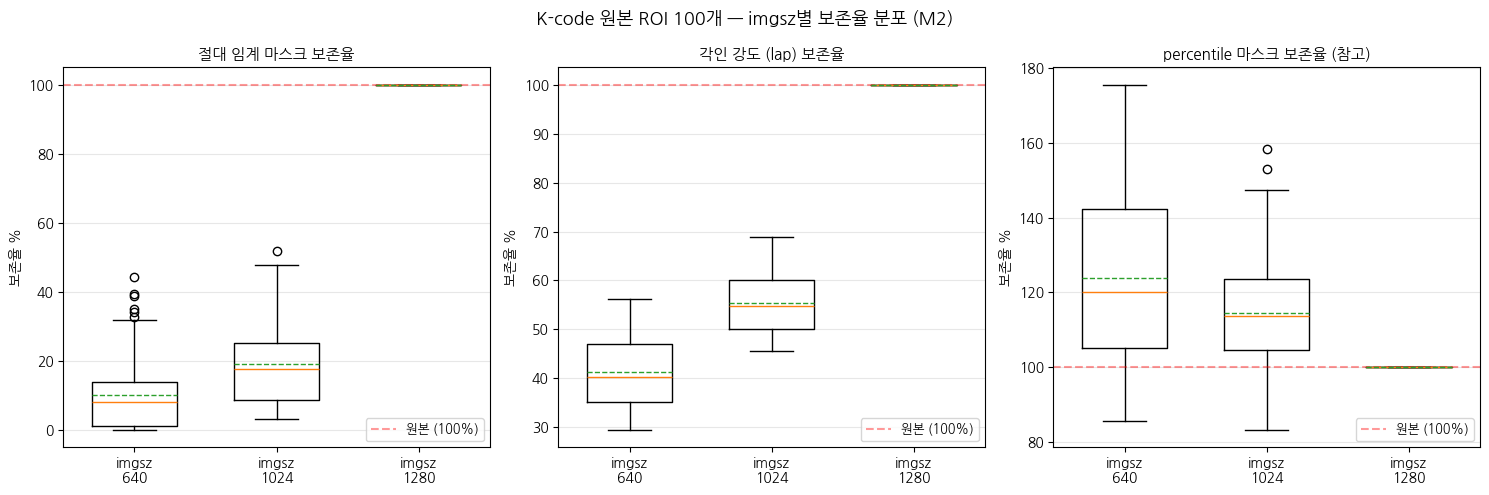

저장: /content/work/analysis/figures/kcode_02_100roi_distribution.png


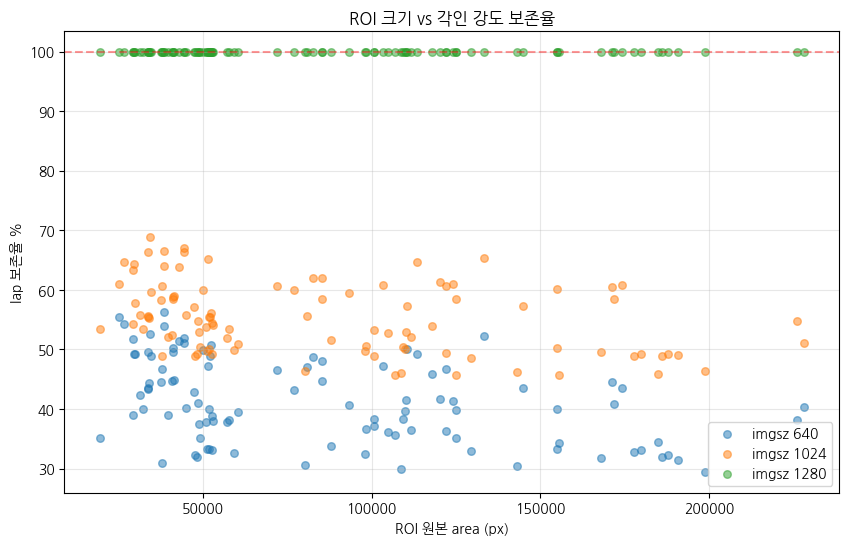

저장: /content/work/analysis/figures/kcode_03_area_vs_preservation.png


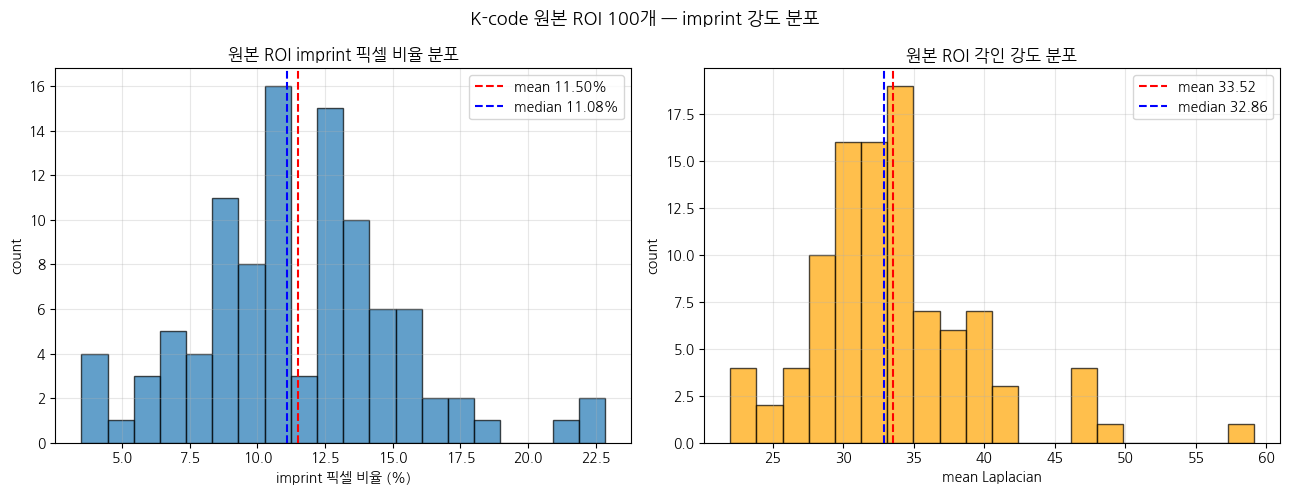

저장: /content/work/analysis/figures/kcode_04_imprint_intensity_dist.png


In [9]:
## 셀 — 시각화 (boxplot 3개 + area vs preservation scatter + imprint 강도 히스토그램)

# ── boxplot 3개 (abs / lap / pct) ──
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = [
    ('abs_pres_%', '절대 임계 마스크 보존율'),
    ('lap_pres_%', '각인 강도 (lap) 보존율'),
    ('pct_pres_%', 'percentile 마스크 보존율 (참고)'),
]
for ax, (col, title) in zip(axes, metrics):
    data = [df_kcode[df_kcode['imgsz']==sz][col].values for sz in DOWNSAMPLE_TARGETS]
    bp = ax.boxplot(data, labels=[f'imgsz\n{sz}' for sz in DOWNSAMPLE_TARGETS],
                    showmeans=True, meanline=True, widths=0.6)
    ax.axhline(100, color='red', linestyle='--', alpha=0.4, label='원본 (100%)')
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('보존율 %')
    ax.grid(alpha=0.3, axis='y')
    ax.legend(loc='lower right', fontsize=9)

plt.suptitle(f"K-code 원본 ROI 100개 — imgsz별 보존율 분포 (M2)", fontsize=13)
plt.tight_layout()

out = FIG_DIR / "kcode_02_100roi_distribution.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out}")


# ── ROI 크기 vs lap_pres scatter ──
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
for imgsz in DOWNSAMPLE_TARGETS:
    sub = df_kcode[df_kcode['imgsz']==imgsz]
    ax.scatter(sub['crop_area'], sub['lap_pres_%'], alpha=0.5, label=f'imgsz {imgsz}', s=30)
ax.axhline(100, color='red', linestyle='--', alpha=0.4)
ax.set_xlabel('ROI 원본 area (px)')
ax.set_ylabel('lap 보존율 %')
ax.set_title('ROI 크기 vs 각인 강도 보존율')
ax.legend()
ax.grid(alpha=0.3)

out2 = FIG_DIR / "kcode_03_area_vs_preservation.png"
plt.savefig(out2, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out2}")


# ── 원본 ROI imprint 강도 분포 ──
orig_only = df_kcode[df_kcode['imgsz']==640][['orig_abs_%', 'orig_lap', 'crop_area']]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(orig_only['orig_abs_%'], bins=20, edgecolor='black', alpha=0.7)
axes[0].axvline(orig_only['orig_abs_%'].mean(), color='red', linestyle='--', label=f"mean {orig_only['orig_abs_%'].mean():.2f}%")
axes[0].axvline(orig_only['orig_abs_%'].median(), color='blue', linestyle='--', label=f"median {orig_only['orig_abs_%'].median():.2f}%")
axes[0].set_xlabel('imprint 픽셀 비율 (%)')
axes[0].set_ylabel('count')
axes[0].set_title('원본 ROI imprint 픽셀 비율 분포')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(orig_only['orig_lap'], bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1].axvline(orig_only['orig_lap'].mean(), color='red', linestyle='--', label=f"mean {orig_only['orig_lap'].mean():.2f}")
axes[1].axvline(orig_only['orig_lap'].median(), color='blue', linestyle='--', label=f"median {orig_only['orig_lap'].median():.2f}")
axes[1].set_xlabel('mean Laplacian')
axes[1].set_ylabel('count')
axes[1].set_title('원본 ROI 각인 강도 분포')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('K-code 원본 ROI 100개 — imprint 강도 분포', fontsize=13)
plt.tight_layout()

out3 = FIG_DIR / "kcode_04_imprint_intensity_dist.png"
plt.savefig(out3, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out3}")

In [10]:
## 셀 — rembg + onnxruntime-gpu 설치 (numpy 1 호환 버전)

# isnet-general-use 모델 사용 (합성 코드와 동일)
# numpy 1.26.4 깨지 않도록 옛 rembg 버전
# Colab 은 GPU 가능 → onnxruntime-gpu

!pip install --quiet "rembg==2.0.50" "onnxruntime-gpu==1.16.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.1/157.1 MB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 111.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 102.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.2.3 which is incompatible.
plotnine 0.14.6 requires scipy<1.16.0,>=1.8.0, but you have scipy 1.17.1 which is incompatible.


In [1]:
## 셀 — 정본 환경 + rembg 검증

import sys

# 영향받은 모듈 캐시 제거 (numpy/pillow/cv2 등 - rembg 설치로 다시 로드된 경우 대비)
for mod_name in list(sys.modules.keys()):
    if any(mod_name.startswith(p) for p in ['numpy', 'PIL', 'cv2', 'rembg', 'onnxruntime', 'pymatting']):
        del sys.modules[mod_name]

import numpy
import PIL
import cv2

print("[정본 환경 유지 확인]")
print(f"  numpy : {numpy.__version__}  (정본 1.26.4)")
print(f"  PIL   : {PIL.__version__}    (정본 10.4.0)")
print(f"  cv2   : {cv2.__version__}    (정본 4.10.0)")


# rembg + onnxruntime
print("\n[rembg + onnxruntime]")
import rembg
import onnxruntime
print(f"  rembg          : {rembg.__version__}")
print(f"  onnxruntime    : {onnxruntime.__version__}")
print(f"  available providers: {onnxruntime.get_available_providers()}")


# rembg import 테스트
from rembg import remove, new_session
print(f"\n  remove, new_session import OK")

/tmp/ipython-input-1-2854214507.py:10: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy


[정본 환경 유지 확인]
  numpy : 2.0.2  (정본 1.26.4)
  PIL   : 10.4.0    (정본 10.4.0)
  cv2   : 4.13.0    (정본 4.10.0)

[rembg + onnxruntime]



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.11/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    ColabKernelApp.launch_instance()
  File "/usr/local/lib/python3.11/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/usr/local/lib/python3.11/dist-packages/ipykernel/kernelapp.py", line 712, in start
    self.io_loop.start()
  File "/usr/local/lib/python3.11/dist-package

AttributeError: _ARRAY_API not found

SystemError: <built-in function __import__> returned a result with an exception set

  rembg          : 2.0.50
  onnxruntime    : 1.16.3
  available providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']

  remove, new_session import OK


In [2]:
!pip list 2>&1 | grep -iE "^(numpy|pillow|opencv|rembg|onnxruntime|pymatting|scipy|pandas) " | sort

numpy                                 2.0.2
onnxruntime                           1.25.1
pandas                                2.2.3
pillow                                10.4.0
PyMatting                             1.1.15
rembg                                 2.0.50
scipy                                 1.17.1


In [3]:
!pip list 2>&1 | grep -iE "^(opencv|onnxruntime)" | sort

onnxruntime                           1.25.1
onnxruntime-gpu                       1.16.3
opencv-contrib-python                 4.11.0.86
opencv-python                         4.10.0.84
opencv-python-headless                4.13.0.92


In [1]:
## 셀 — opencv 정리 + onnxruntime 정리 + numpy 정본 복구

# 1) 부주의 설치된 것들 제거
!pip uninstall -y opencv-python-headless opencv-contrib-python onnxruntime

# 2) opencv-python 4.10 강제 재설치 (cv2 폴더 손상 가능성 대비)
!pip install --force-reinstall --no-deps "opencv-python==4.10.0.84"

# 3) numpy + pillow 정본 복구
!pip install --no-deps "numpy==1.26.4" "pillow==10.4.0"

  Using cached opencv_python-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (62.5 MB)
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.10.0.84
    Uninstalling opencv-python-4.10.0.84:
      Successfully uninstalled opencv-python-4.10.0.84
  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2


In [2]:
!pip list 2>&1 | grep -iE "^(onnxruntime|opencv)" | sort

onnxruntime-gpu                       1.16.3
opencv-python                         4.10.0.84


In [3]:
import onnxruntime
print(f"onnxruntime path: {onnxruntime.__file__}")
print(f"version: {onnxruntime.__version__}")
print(f"dir(onnxruntime): {[x for x in dir(onnxruntime) if not x.startswith('_')][:20]}")

onnxruntime path: None


AttributeError: module 'onnxruntime' has no attribute '__version__'

In [4]:
!pip install --force-reinstall --no-deps "onnxruntime-gpu==1.16.3"

  Using cached onnxruntime_gpu-1.16.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.3 kB)
Using cached onnxruntime_gpu-1.16.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (157.1 MB)
  Attempting uninstall: onnxruntime-gpu
    Found existing installation: onnxruntime-gpu 1.16.3
    Uninstalling onnxruntime-gpu-1.16.3:
      Successfully uninstalled onnxruntime-gpu-1.16.3


In [1]:
import sys
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith('onnxruntime') or mod_name.startswith('rembg'):
        del sys.modules[mod_name]

import onnxruntime
print(f"onnxruntime: {onnxruntime.__version__}")
print(f"path: {onnxruntime.__file__}")
print(f"providers: {onnxruntime.get_available_providers()}")

from rembg import remove, new_session
print("rembg import OK")

onnxruntime: 1.16.3
path: /usr/local/lib/python3.11/dist-packages/onnxruntime/__init__.py
providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']
rembg import OK


In [6]:
import os
from pathlib import Path

candidates = {
    '/content/dataset_yolo': '폴더 (unzip 결과)',
    '/content/clean_df.csv': '파일',
    '/content/dataset_yolo.zip': '파일',
    '/content/work': '작업 폴더',
}

for p, desc in candidates.items():
    pth = Path(p)
    if pth.exists():
        if pth.is_dir():
            n = len(list(pth.iterdir()))
            print(f"  ✓ {p} ({desc}) — 항목 {n}개")
        else:
            size_mb = pth.stat().st_size / 1024 / 1024
            print(f"  ✓ {p} ({desc}) — {size_mb:.1f} MB")
    else:
        print(f"  ✗ {p} ({desc}) — 없음")

  ✓ /content/dataset_yolo (폴더 (unzip 결과)) — 항목 3개
  ✓ /content/clean_df.csv (파일) — 28.1 MB
  ✓ /content/dataset_yolo.zip (파일) — 17926.7 MB
  ✓ /content/work (작업 폴더) — 항목 1개


In [7]:
## 셀 — 모든 변수 재정의 (디스크 보존 활용)

from pathlib import Path
import json
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Drive API 재인증
from google.colab import auth
auth.authenticate_user()
from googleapiclient.discovery import build
drive_service = build('drive', 'v3')


# ── 경로 ──
ROOT = Path('/content/work')
ANALYSIS_DIR = ROOT / 'analysis'
FIG_DIR = ANALYSIS_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

DATASET_YOLO_DIR = Path('/content/dataset_yolo')
DATASET_ZIP_LOCAL = Path('/content/dataset_yolo.zip')
CLEAN_DF_LOCAL = Path('/content/clean_df.csv')

TRAIN_DIR = DATASET_YOLO_DIR / 'images' / 'train'
VAL_DIR = DATASET_YOLO_DIR / 'images' / 'val'


# ── 한글 폰트 ──
NANUM_LOCAL = Path('/content/NanumGothic.ttf')
if NANUM_LOCAL.exists():
    fm.fontManager.addfont(str(NANUM_LOCAL))
    plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False


# ── 헬퍼 ──
def imread_kr(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)

def find_image_path(file_name):
    p_train = TRAIN_DIR / file_name
    if p_train.exists():
        return p_train
    p_val = VAL_DIR / file_name
    if p_val.exists():
        return p_val
    return None


# ── clean_df 로드 ──
df_clean = pd.read_csv(CLEAN_DF_LOCAL, low_memory=False)
print(f"df_clean: {df_clean.shape}")


# ── 측정 풀 ──
pool_df = df_clean[df_clean['image_exists'].notna()].reset_index(drop=True)
print(f"pool_df: {len(pool_df)}행")


# ── 100 ROI 샘플 인덱스 ──
N_SAMPLE = 100
SEED_C = 2026
rng_c = np.random.default_rng(SEED_C)
sample_idx = rng_c.choice(len(pool_df), N_SAMPLE, replace=False)
print(f"sample_idx: {len(sample_idx)}개 (seed={SEED_C})")


# ── 측정 함수 (RGB) ──
def measure_kcode(rgb, abs_threshold, ksize=3, percentile=90):
    if rgb.ndim == 3 and rgb.shape[2] == 4:
        rgb = rgb[:, :, :3]
    h, w = rgb.shape[:2]
    pill_px = h * w
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=ksize)
    lap_abs = np.abs(lap)
    pct_thr = np.percentile(lap_abs, percentile)
    mask_pct = lap_abs >= pct_thr
    mask_abs = lap_abs >= abs_threshold
    return {
        'pill_px': pill_px,
        'mask_pct': mask_pct,
        'ratio_pct': mask_pct.sum() / pill_px,
        'mask_abs': mask_abs,
        'ratio_abs': mask_abs.sum() / pill_px,
        'mean_lap': float(lap_abs[mask_pct].mean()) if mask_pct.any() else 0.0,
        'lap_abs': lap_abs,
    }

def measure_m2_kcode(rgb, scale, abs_threshold, ksize=3):
    h, w = rgb.shape[:2]
    nw = max(1, int(round(w * scale)))
    nh = max(1, int(round(h * scale)))
    rgb_ds = cv2.resize(rgb, (nw, nh), interpolation=cv2.INTER_AREA)
    rgb_up = cv2.resize(rgb_ds, (w, h), interpolation=cv2.INTER_LINEAR)
    return measure_kcode(rgb_up, abs_threshold, ksize=ksize)


# ── ABS_THRESHOLD 박제값 (이미 검증된 값, 재계산 생략) ──
ABS_THRESHOLD_KCODE = 24.00
print(f"ABS_THRESHOLD_KCODE: {ABS_THRESHOLD_KCODE}")


print("\n[재정의 완료]")
print(f"  TRAIN_DIR: {TRAIN_DIR.exists()}")
print(f"  VAL_DIR: {VAL_DIR.exists()}")

df_clean: (39864, 45)
pool_df: 39131행
sample_idx: 100개 (seed=2026)
ABS_THRESHOLD_KCODE: 24.0

[재정의 완료]
  TRAIN_DIR: True
  VAL_DIR: True


[rembg 세션 초기화 — isnet-general-use]
EP Error /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:1193 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library libonnxruntime_providers_tensorrt.so with error: libcudnn.so.8: cannot open shared object file: No such file or directory
 when using ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']
Falling back to ['CUDAExecutionProvider', 'CPUExecutionProvider'] and retrying.
  세션 생성: 2.09초

[1개 ROI 처리]
  file: K-015710-027733-029667-034597_0_2_0_2_75_000_200.png
  crop shape: (215, 220, 3)

  warmup...
  warmup 완료: 9.549초

  rembg remove (실측): 3.750초
  alpha > 128 비율: 0.647 (기준 0.35)
  is_valid_crop: True


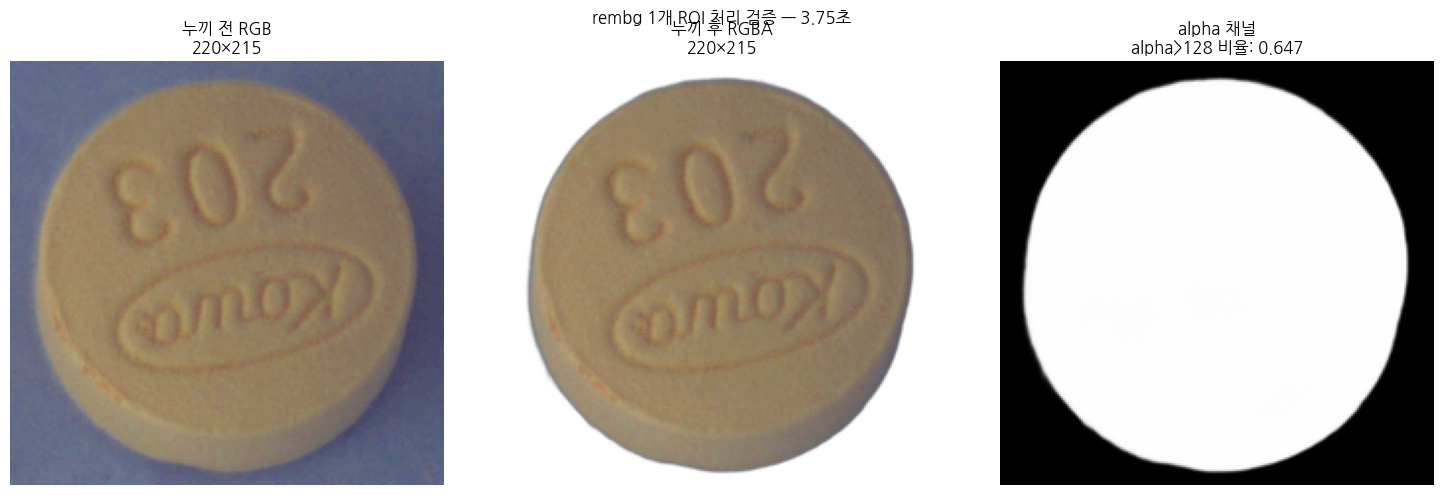


저장: /content/work/analysis/figures/kcode_05_rembg_check.png

100 ROI 예상 시간: 375초 (≈ 6.3분)


In [8]:
## 셀 — rembg 1개 ROI 처리 시간 측정 (isnet-general-use)

import time
from rembg import remove, new_session

# 합성 코드와 동일 모델, 옵션 없음
print("[rembg 세션 초기화 — isnet-general-use]")
t0 = time.time()
session = new_session("isnet-general-use")
print(f"  세션 생성: {time.time()-t0:.2f}초")


# 합성 코드 동일 alpha 검증 함수
MIN_ALPHA_RATIO = 0.35

def is_valid_crop(rgba_pil, min_alpha_ratio=MIN_ALPHA_RATIO):
    alpha = np.array(rgba_pil)[:, :, 3]
    return (alpha > 128).mean() >= min_alpha_ratio


# 1개 ROI 처리
sample_row = pool_df.iloc[sample_idx[0]]
img_path = find_image_path(sample_row['file_name'])
img_bgr = imread_kr(img_path)
rgb_full = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
x, y, w, h = int(sample_row['bbox_x']), int(sample_row['bbox_y']), int(sample_row['bbox_w']), int(sample_row['bbox_h'])
crop_rgb = rgb_full[y:y+h, x:x+w]
print(f"\n[1개 ROI 처리]")
print(f"  file: {sample_row['file_name']}")
print(f"  crop shape: {crop_rgb.shape}")


pil_in = Image.fromarray(crop_rgb)

# Warmup 1회
print(f"\n  warmup...")
t0 = time.time()
_ = remove(pil_in, session=session)
print(f"  warmup 완료: {time.time()-t0:.3f}초")

# 본 측정
t0 = time.time()
pil_out = remove(pil_in, session=session)
elapsed = time.time() - t0
print(f"\n  rembg remove (실측): {elapsed:.3f}초")

alpha_ratio = (np.array(pil_out)[:, :, 3] > 128).mean()
valid = is_valid_crop(pil_out)
print(f"  alpha > 128 비율: {alpha_ratio:.3f} (기준 {MIN_ALPHA_RATIO})")
print(f"  is_valid_crop: {valid}")


# 시각 비교
rgba_out = np.array(pil_out)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(crop_rgb)
axes[0].set_title(f"누끼 전 RGB\n{crop_rgb.shape[1]}×{crop_rgb.shape[0]}")
axes[0].axis('off')

axes[1].imshow(rgba_out)
axes[1].set_title(f"누끼 후 RGBA\n{rgba_out.shape[1]}×{rgba_out.shape[0]}")
axes[1].axis('off')

axes[2].imshow(rgba_out[:, :, 3], cmap='gray')
axes[2].set_title(f"alpha 채널\nalpha>128 비율: {alpha_ratio:.3f}")
axes[2].axis('off')

plt.suptitle(f"rembg 1개 ROI 처리 검증 — {elapsed:.2f}초", fontsize=12)
plt.tight_layout()

out = FIG_DIR / "kcode_05_rembg_check.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n저장: {out}")
print(f"\n100 ROI 예상 시간: {elapsed*100:.0f}초 (≈ {elapsed*100/60:.1f}분)")

In [9]:
## 셀 — 100 ROI rembg 누끼 + 누끼 전후 페어 측정

import time
from tqdm.auto import tqdm

# ── 누끼 후 측정 함수 (alpha 채널로 마스킹 + 외곽 침식 2회) ──
def measure_kcode_rgba(rgba, abs_threshold, ksize=3, percentile=90, erode_iter=2):
    """
    누끼 후 RGBA crop 측정. alpha 로 알약 영역 마스킹 + 외곽 침식.
    """
    rgb = rgba[:, :, :3]
    alpha_raw = (rgba[:, :, 3] > 128).astype(np.uint8)

    # 외곽 침식 (rembg soft edge boundary lap 노이즈 제거)
    kernel = np.ones((3, 3), np.uint8)
    alpha = cv2.erode(alpha_raw, kernel, iterations=erode_iter).astype(bool)

    pill_px = int(alpha.sum())
    if pill_px == 0:
        return {'pill_px': 0, 'ratio_pct': 0.0, 'ratio_abs': 0.0, 'mean_lap': 0.0}

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=ksize)
    lap_abs = np.abs(lap)

    pill_lap = lap_abs[alpha]
    pct_thr = np.percentile(pill_lap, percentile)
    mask_pct = (lap_abs >= pct_thr) & alpha
    mask_abs = (lap_abs >= abs_threshold) & alpha

    return {
        'pill_px': pill_px,
        'ratio_pct': mask_pct.sum() / pill_px,
        'ratio_abs': mask_abs.sum() / pill_px,
        'mean_lap': float(lap_abs[mask_pct].mean()) if mask_pct.any() else 0.0,
    }


# ── 100 ROI 본격 측정 ──
records_rembg = []
n_skipped = 0
n_invalid_crop = 0  # alpha > 128 비율 < 0.35
total_rembg_time = 0.0

print(f"[100 ROI rembg 누끼 + 누끼 전후 측정 시작]")
t_start = time.time()

for i, idx in enumerate(tqdm(sample_idx, desc='rembg')):
    row = pool_df.iloc[idx]
    img_path = find_image_path(row['file_name'])
    if img_path is None:
        n_skipped += 1
        continue
    img_bgr = imread_kr(img_path)
    if img_bgr is None:
        n_skipped += 1
        continue
    rgb_full = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    x, y, w, h = int(row['bbox_x']), int(row['bbox_y']), int(row['bbox_w']), int(row['bbox_h'])
    crop_rgb = rgb_full[y:y+h, x:x+w]
    if crop_rgb.size == 0 or crop_rgb.shape[0] < 8 or crop_rgb.shape[1] < 8:
        n_skipped += 1
        continue

    # 누끼 전 측정 (RGB 전체 영역)
    m_pre = measure_kcode(crop_rgb, ABS_THRESHOLD_KCODE, ksize=3)

    # rembg 누끼 (시간 측정)
    pil_in = Image.fromarray(crop_rgb)
    t_rembg = time.time()
    pil_out = remove(pil_in, session=session)
    rembg_elapsed = time.time() - t_rembg
    total_rembg_time += rembg_elapsed

    rgba_out = np.array(pil_out)
    alpha_ratio = (rgba_out[:, :, 3] > 128).mean()

    # alpha 검증 (합성 코드와 동일 기준)
    if alpha_ratio < MIN_ALPHA_RATIO:
        n_invalid_crop += 1
        # 측정은 진행 (분석용으로 alpha_ratio 같이 기록)

    # 누끼 후 측정 (alpha 채널 마스킹 + 외곽 침식)
    m_post = measure_kcode_rgba(rgba_out, ABS_THRESHOLD_KCODE, ksize=3, erode_iter=2)

    records_rembg.append({
        'file_name': row['file_name'],
        'dl_name': row['dl_name'],
        'crop_w': crop_rgb.shape[1], 'crop_h': crop_rgb.shape[0],
        'crop_area': crop_rgb.shape[0] * crop_rgb.shape[1],
        'rembg_seconds': rembg_elapsed,
        'alpha_ratio': alpha_ratio,
        'is_valid_crop': alpha_ratio >= MIN_ALPHA_RATIO,
        'pre_pill_px': m_pre['pill_px'],
        'pre_ratio_abs_%': m_pre['ratio_abs'] * 100,
        'pre_mean_lap': m_pre['mean_lap'],
        'post_pill_px': m_post['pill_px'],
        'post_ratio_abs_%': m_post['ratio_abs'] * 100,
        'post_mean_lap': m_post['mean_lap'],
        # 보존율 (post / pre)
        'lap_pres_%': (m_post['mean_lap']/m_pre['mean_lap']*100) if m_pre['mean_lap']>0 else 0,
    })

t_total = time.time() - t_start
df_rembg = pd.DataFrame(records_rembg)

print(f"\n[측정 완료]")
print(f"  총 시간: {t_total:.1f}초 ({t_total/60:.1f}분)")
print(f"  rembg 순수 시간: {total_rembg_time:.1f}초 (평균 {total_rembg_time/len(df_rembg):.2f}초/ROI)")
print(f"  측정 행: {len(df_rembg)}행")
print(f"  스킵: {n_skipped}건")
print(f"  alpha < {MIN_ALPHA_RATIO} (invalid_crop): {n_invalid_crop}건 / {len(df_rembg)}건 ({n_invalid_crop/len(df_rembg)*100:.1f}%)")


# ── 누끼 전후 비교 통계 ──
print("\n[누끼 전후 측정값 분포]")
print(f"{'metric':>20} | {'mean':>8} {'median':>8} {'std':>7}")
print("-" * 60)
for label, col in [
    ('누끼 전 ratio_abs %', 'pre_ratio_abs_%'),
    ('누끼 후 ratio_abs %', 'post_ratio_abs_%'),
    ('누끼 전 mean_lap', 'pre_mean_lap'),
    ('누끼 후 mean_lap', 'post_mean_lap'),
    ('lap 보존율 % (post/pre)', 'lap_pres_%'),
]:
    vals = df_rembg[col]
    print(f"{label:>20} | {vals.mean():>8.2f} {vals.median():>8.2f} {vals.std():>7.2f}")


# ── 페어 비교 (같은 ROI 누끼 전 vs 누끼 후) ──
diff_lap = df_rembg['post_mean_lap'] - df_rembg['pre_mean_lap']
diff_abs = df_rembg['post_ratio_abs_%'] - df_rembg['pre_ratio_abs_%']

print(f"\n[페어 비교 — 같은 ROI 누끼 후 - 누끼 전]")
print(f"  mean_lap   : mean {diff_lap.mean():+.2f}, median {diff_lap.median():+.2f}")
print(f"  ratio_abs %: mean {diff_abs.mean():+.2f}, median {diff_abs.median():+.2f}")


# ── 누끼 처리 시간 분포 ──
print(f"\n[rembg 처리 시간 분포 (sec/ROI)]")
print(f"  mean {df_rembg['rembg_seconds'].mean():.2f}, "
      f"median {df_rembg['rembg_seconds'].median():.2f}, "
      f"min {df_rembg['rembg_seconds'].min():.2f}, "
      f"max {df_rembg['rembg_seconds'].max():.2f}")


# ── 결과 csv 저장 (Drive 업로드 대비) ──
csv_out = ANALYSIS_DIR / 'kcode_rembg_results.csv'
df_rembg.to_csv(csv_out, index=False)
print(f"\n[저장] {csv_out}")

[100 ROI rembg 누끼 + 누끼 전후 측정 시작]


rembg:   0%|          | 0/100 [00:00<?, ?it/s]


[측정 완료]
  총 시간: 380.0초 (6.3분)
  rembg 순수 시간: 374.9초 (평균 3.75초/ROI)
  측정 행: 100행
  스킵: 0건
  alpha < 0.35 (invalid_crop): 7건 / 100건 (7.0%)

[누끼 전후 측정값 분포]
              metric |     mean   median     std
------------------------------------------------------------
    누끼 전 ratio_abs % |    11.50    11.08    3.73
    누끼 후 ratio_abs % |     8.29     8.58    5.17
       누끼 전 mean_lap |    33.52    32.86    5.93
       누끼 후 mean_lap |    27.91    28.75    8.60
lap 보존율 % (post/pre) |    83.53    88.31   22.36

[페어 비교 — 같은 ROI 누끼 후 - 누끼 전]
  mean_lap   : mean -5.61, median -3.99
  ratio_abs %: mean -3.22, median -2.78

[rembg 처리 시간 분포 (sec/ROI)]
  mean 3.75, median 3.39, min 3.21, max 6.87

[저장] /content/work/analysis/kcode_rembg_results.csv


/tmp/ipython-input-10-1768372525.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data_abs, labels=['누끼 전\n(RGB 전체)', '누끼 후\n(alpha 마스킹)'],
/tmp/ipython-input-10-1768372525.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_lap, labels=['누끼 전\n(RGB 전체)', '누끼 후\n(alpha 마스킹)'],


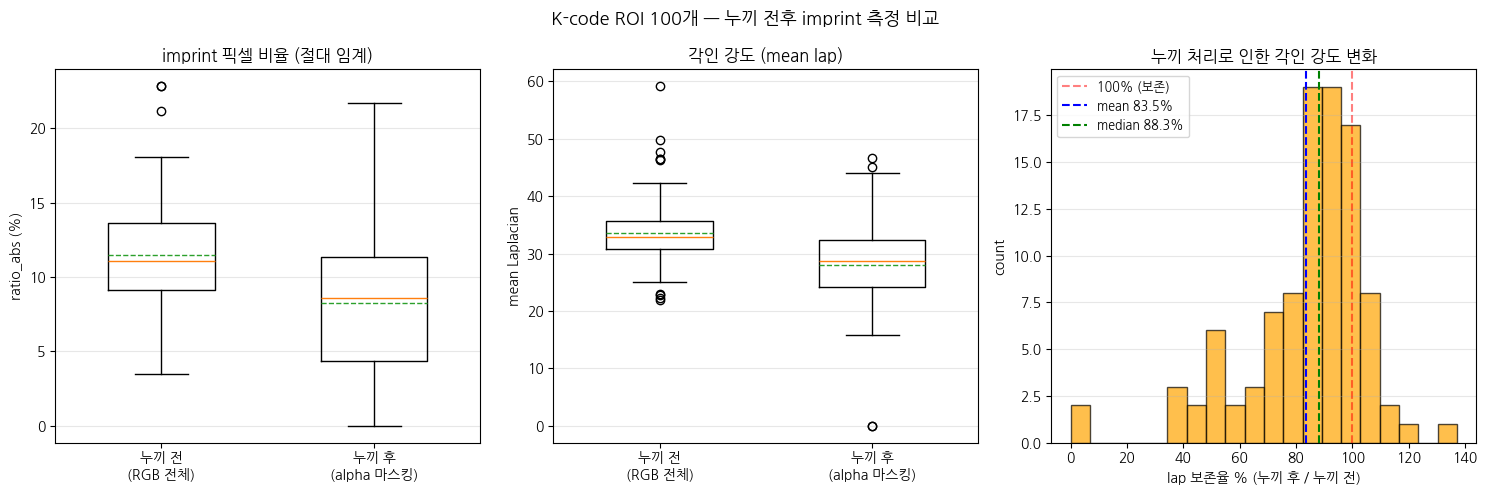

저장: /content/work/analysis/figures/kcode_06_rembg_pre_vs_post.png


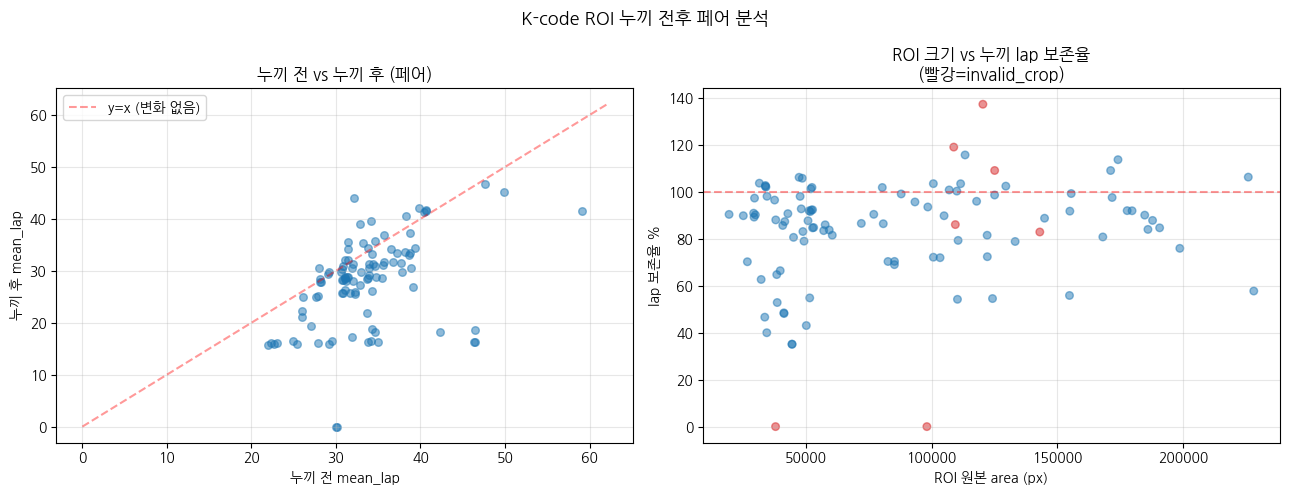

저장: /content/work/analysis/figures/kcode_07_rembg_pair_scatter.png

[invalid_crop 7건 — alpha 비율 낮은 순]
                                           file_name            dl_name  crop_w  crop_h  alpha_ratio  lap_pres_%
       K-005391-013900-016688_0_2_0_2_75_000_200.png              프로스카정     204     186     0.000000    0.000000
K-010487-026993-035659-044266_0_2_0_2_75_000_200.png  동화덴스톨캡슐 150mg/PTP     223     440     0.000815    0.000000
K-012638-023319-035659-043233_0_2_0_2_90_000_200.png  투스딘골드캡슐 150mg/PTP     235     463     0.005367  118.927696
K-000573-005094-013161-022627_0_2_0_2_90_000_200.png     엘스테인캡슐(에르도스테인)     254     474     0.249635  137.158289
K-005002-005094-012081-023223_0_2_0_2_70_000_200.png 엘도스캡슐(에르도스테인)(수출용)     265     472     0.279389  108.976458
K-012638-019881-029711-043233_0_2_0_2_90_000_200.png  투스딘골드캡슐 150mg/PTP     417     343     0.317658   82.808827
K-004378-019552-025438-037777_0_2_0_2_70_000_200.png    알바스테인캡슐(에르도스테인)     228     480     0.340515   85.9

In [10]:
## 셀 — 누끼 전후 비교 시각화

# ── 1. 누끼 전후 페어 비교 boxplot ──
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# (1) ratio_abs 분포 비교
data_abs = [df_rembg['pre_ratio_abs_%'].values, df_rembg['post_ratio_abs_%'].values]
axes[0].boxplot(data_abs, labels=['누끼 전\n(RGB 전체)', '누끼 후\n(alpha 마스킹)'],
                showmeans=True, meanline=True, widths=0.5)
axes[0].set_ylabel('ratio_abs (%)')
axes[0].set_title('imprint 픽셀 비율 (절대 임계)')
axes[0].grid(alpha=0.3, axis='y')

# (2) mean_lap 분포 비교
data_lap = [df_rembg['pre_mean_lap'].values, df_rembg['post_mean_lap'].values]
axes[1].boxplot(data_lap, labels=['누끼 전\n(RGB 전체)', '누끼 후\n(alpha 마스킹)'],
                showmeans=True, meanline=True, widths=0.5)
axes[1].set_ylabel('mean Laplacian')
axes[1].set_title('각인 강도 (mean lap)')
axes[1].grid(alpha=0.3, axis='y')

# (3) lap 보존율 (post/pre) 히스토그램
axes[2].hist(df_rembg['lap_pres_%'], bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[2].axvline(100, color='red', linestyle='--', alpha=0.5, label='100% (보존)')
axes[2].axvline(df_rembg['lap_pres_%'].mean(), color='blue', linestyle='--',
                label=f"mean {df_rembg['lap_pres_%'].mean():.1f}%")
axes[2].axvline(df_rembg['lap_pres_%'].median(), color='green', linestyle='--',
                label=f"median {df_rembg['lap_pres_%'].median():.1f}%")
axes[2].set_xlabel('lap 보존율 % (누끼 후 / 누끼 전)')
axes[2].set_ylabel('count')
axes[2].set_title('누끼 처리로 인한 각인 강도 변화')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3, axis='y')

plt.suptitle('K-code ROI 100개 — 누끼 전후 imprint 측정 비교', fontsize=13)
plt.tight_layout()

out = FIG_DIR / 'kcode_06_rembg_pre_vs_post.png'
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out}")


# ── 2. 페어 scatter (누끼 전 mean_lap vs 누끼 후 mean_lap) ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (1) pre vs post scatter
axes[0].scatter(df_rembg['pre_mean_lap'], df_rembg['post_mean_lap'], alpha=0.5, s=30)
xy_max = max(df_rembg['pre_mean_lap'].max(), df_rembg['post_mean_lap'].max()) * 1.05
axes[0].plot([0, xy_max], [0, xy_max], 'r--', alpha=0.4, label='y=x (변화 없음)')
axes[0].set_xlabel('누끼 전 mean_lap')
axes[0].set_ylabel('누끼 후 mean_lap')
axes[0].set_title('누끼 전 vs 누끼 후 (페어)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# (2) crop_area vs lap 보존율
axes[1].scatter(df_rembg['crop_area'], df_rembg['lap_pres_%'],
                alpha=0.5, s=30,
                c=df_rembg['is_valid_crop'].map({True: 'tab:blue', False: 'tab:red'}))
axes[1].axhline(100, color='red', linestyle='--', alpha=0.4)
axes[1].set_xlabel('ROI 원본 area (px)')
axes[1].set_ylabel('lap 보존율 %')
axes[1].set_title('ROI 크기 vs 누끼 lap 보존율\n(빨강=invalid_crop)')
axes[1].grid(alpha=0.3)

plt.suptitle('K-code ROI 누끼 전후 페어 분석', fontsize=13)
plt.tight_layout()

out2 = FIG_DIR / 'kcode_07_rembg_pair_scatter.png'
plt.savefig(out2, dpi=120, bbox_inches='tight')
plt.show()
print(f"저장: {out2}")


# ── 3. invalid_crop 7건 시각 (어떤 ROI 가 alpha 0.35 미만인지) ──
invalid = df_rembg[~df_rembg['is_valid_crop']].sort_values('alpha_ratio')
print(f"\n[invalid_crop 7건 — alpha 비율 낮은 순]")
print(invalid[['file_name', 'dl_name', 'crop_w', 'crop_h', 'alpha_ratio', 'lap_pres_%']].to_string(index=False))

In [11]:
## 셀 — 결과 csv + figure 들 Drive 업로드 (pill_detection_3팀/seungwon/analysis/)

from googleapiclient.http import MediaFileUpload

# 본인 폴더 ID 찾기 (세션 새로 시작했을 수 있어서 재검색)
res = drive_service.files().list(
    q="name='pill_detection_3팀' and mimeType='application/vnd.google-apps.folder' and trashed=false",
    fields='files(id, name)'
).execute()
team_folder = res['files'][0]
TEAM_FOLDER_ID = team_folder['id']

res = drive_service.files().list(
    q=f"'{TEAM_FOLDER_ID}' in parents and name='seungwon' and mimeType='application/vnd.google-apps.folder' and trashed=false",
    fields='files(id, name)'
).execute()
my_folder = res['files'][0]
MY_FOLDER_ID = my_folder['id']
print(f"MY_FOLDER_ID: {MY_FOLDER_ID}  (pill_detection_3팀/seungwon/)")


# analysis 하위폴더 — 없으면 생성
res = drive_service.files().list(
    q=f"'{MY_FOLDER_ID}' in parents and name='analysis' and mimeType='application/vnd.google-apps.folder' and trashed=false",
    fields='files(id, name)'
).execute()
if res['files']:
    ANALYSIS_DRIVE_ID = res['files'][0]['id']
    print(f"analysis 폴더 이미 존재: {ANALYSIS_DRIVE_ID}")
else:
    folder_metadata = {
        'name': 'analysis',
        'mimeType': 'application/vnd.google-apps.folder',
        'parents': [MY_FOLDER_ID],
    }
    folder = drive_service.files().create(body=folder_metadata, fields='id').execute()
    ANALYSIS_DRIVE_ID = folder['id']
    print(f"analysis 폴더 생성: {ANALYSIS_DRIVE_ID}")


# 업로드할 파일 목록
upload_files = [
    ('kcode_rembg_results.csv', ANALYSIS_DIR / 'kcode_rembg_results.csv'),
    ('kcode_05_rembg_check.png', FIG_DIR / 'kcode_05_rembg_check.png'),
    ('kcode_06_rembg_pre_vs_post.png', FIG_DIR / 'kcode_06_rembg_pre_vs_post.png'),
    ('kcode_07_rembg_pair_scatter.png', FIG_DIR / 'kcode_07_rembg_pair_scatter.png'),
    # 측정 1·3 figure 들도 같이 (이미 본인 venv 에 있지만 Colab 결과도 보존)
    ('kcode_02_100roi_distribution.png', FIG_DIR / 'kcode_02_100roi_distribution.png'),
    ('kcode_03_area_vs_preservation.png', FIG_DIR / 'kcode_03_area_vs_preservation.png'),
    ('kcode_04_imprint_intensity_dist.png', FIG_DIR / 'kcode_04_imprint_intensity_dist.png'),
]


# 업로드 (덮어쓰기)
print("\n[업로드 시작]")
for name, local_path in upload_files:
    if not local_path.exists():
        print(f"  [SKIP] {name}: 로컬 파일 없음 ({local_path})")
        continue

    # 같은 이름 파일 있으면 덮어쓰기
    res = drive_service.files().list(
        q=f"'{ANALYSIS_DRIVE_ID}' in parents and name='{name}' and trashed=false",
        fields='files(id)'
    ).execute()

    media = MediaFileUpload(str(local_path), resumable=False)

    if res['files']:
        # 업데이트
        existing_id = res['files'][0]['id']
        drive_service.files().update(fileId=existing_id, media_body=media).execute()
        print(f"  [업데이트] {name} ({local_path.stat().st_size/1024:.0f} KB)")
    else:
        # 신규 생성
        file_metadata = {'name': name, 'parents': [ANALYSIS_DRIVE_ID]}
        drive_service.files().create(body=file_metadata, media_body=media, fields='id').execute()
        print(f"  [신규] {name} ({local_path.stat().st_size/1024:.0f} KB)")

print("\n[완료]")
print(f"  Drive 경로: pill_detection_3팀/seungwon/analysis/")

MY_FOLDER_ID: 16Fzq3KytjNKK_GgW6wSG9nKLdRyqLJvS  (pill_detection_3팀/seungwon/)
analysis 폴더 생성: 1X50TBm-mseZZEFS2mo49p8m-SmZxi4QZ

[업로드 시작]
  [신규] kcode_rembg_results.csv (24 KB)
  [신규] kcode_05_rembg_check.png (441 KB)
  [신규] kcode_06_rembg_pre_vs_post.png (76 KB)
  [신규] kcode_07_rembg_pair_scatter.png (104 KB)
  [신규] kcode_02_100roi_distribution.png (57 KB)
  [신규] kcode_03_area_vs_preservation.png (62 KB)
  [신규] kcode_04_imprint_intensity_dist.png (60 KB)

[완료]
  Drive 경로: pill_detection_3팀/seungwon/analysis/
